In [5]:
import pandas as pd

In [6]:
df = pd.read_excel("data/data.xlsx")

print(df.shape)
df.head()

(50000, 13)


,Age,Gender,Region,Marital_status,Number Of Dependants,BMI_Category,Smoking_Status,Employment_Status,Income_Level,Income_Lakhs,Medical History,Insurance_Plan,Annual_Premium_Amount
0,26,Male,Northwest,Unmarried,0,Normal,No Smoking,Salaried,<10L,6,Diabetes,Bronze,9053
1,29,Female,Southeast,Married,2,Obesity,Regular,Salaried,<10L,6,Diabetes,Bronze,16339
2,49,Female,Northeast,Married,2,Normal,No Smoking,Self-Employed,10L - 25L,20,High blood pressure,Silver,18164
3,30,Female,Southeast,Married,3,Normal,No Smoking,Salaried,> 40L,77,No Disease,Gold,20303
4,18,Male,Northeast,Unmarried,0,Overweight,Regular,Self-Employed,> 40L,99,High blood pressure,Silver,13365


In [9]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, train_test_split

EDA AND DATA CLEANING

In [10]:
df.columns = df.columns.str.replace(' ', '_').str.lower()  

In [11]:
df.head()

,age,gender,region,marital_status,number_of_dependants,bmi_category,smoking_status,employment_status,income_level,income_lakhs,medical_history,insurance_plan,annual_premium_amount
0,26,Male,Northwest,Unmarried,0,Normal,No Smoking,Salaried,<10L,6,Diabetes,Bronze,9053
1,29,Female,Southeast,Married,2,Obesity,Regular,Salaried,<10L,6,Diabetes,Bronze,16339
2,49,Female,Northeast,Married,2,Normal,No Smoking,Self-Employed,10L - 25L,20,High blood pressure,Silver,18164
3,30,Female,Southeast,Married,3,Normal,No Smoking,Salaried,> 40L,77,No Disease,Gold,20303
4,18,Male,Northeast,Unmarried,0,Overweight,Regular,Self-Employed,> 40L,99,High blood pressure,Silver,13365


In [12]:
df.isna().sum()

age                       0
gender                    0
region                    0
marital_status            0
number_of_dependants      0
bmi_category              0
smoking_status           11
employment_status         2
income_level             13
income_lakhs              0
medical_history           0
insurance_plan            0
annual_premium_amount     0
dtype: int64

In [13]:
#since the dataset size is >>>> na values in dataset we drop them
df.dropna(inplace = True)

HANDLING DUPLICATES

In [15]:
df.duplicated().sum()  #=====> Checking for duplicate values
df.drop_duplicates(inplace = True) #=====> Dropping duplicate records
df.duplicated().sum()  

np.int64(0)

In [16]:
df.describe()

,age,number_of_dependants,income_lakhs,annual_premium_amount
count,49976.000000,49976.000000,49976.000000,49976.000000
mean,34.591764,1.711842,23.021150,15766.810189
std,15.000378,1.498195,24.221794,8419.995271
min,18.000000,-3.000000,1.000000,3501.000000
25%,22.000000,0.000000,7.000000,8607.750000
50%,31.000000,2.000000,17.000000,13928.000000
75%,45.000000,3.000000,31.000000,22273.500000
max,356.000000,5.000000,930.000000,43471.000000


In [17]:
df['medical_history'].unique()

<ArrowStringArray>
[                           'Diabetes',                 'High blood pressure',
                          'No Disease',      'Diabetes & High blood pressure',
                             'Thyroid',                       'Heart disease',
 'High blood pressure & Heart disease',                  'Diabetes & Thyroid',
            'Diabetes & Heart disease']
Length: 9, dtype: str

In [18]:
df['income_level'].unique()

<ArrowStringArray>
['<10L', '10L - 25L', '> 40L', '25L - 40L']
Length: 4, dtype: str

In [19]:
df[df.number_of_dependants < 0].shape

(72, 13)

In [20]:
df[df.number_of_dependants < 0]['number_of_dependants'].unique()

array([-3, -1])

In [21]:
#Some issue while fetching the data, considering these values as positive 
df['number_of_dependants'] = abs(df['number_of_dependants'])  #changing negetive vals to positive
df['number_of_dependants'].describe()

count    49976.000000
mean         1.717284
std          1.491953
min          0.000000
25%          0.000000
50%          2.000000
75%          3.000000
max          5.000000
Name: number_of_dependants, dtype: float64

# HANDLING NUMERICAL COLUMNS

Handling outliers(Outlier Treatment)

In [22]:
numeric_columns = df.select_dtypes(['float64', 'int64']).columns
numeric_columns

Index(['age', 'number_of_dependants', 'income_lakhs', 'annual_premium_amount'],
      dtype='str')

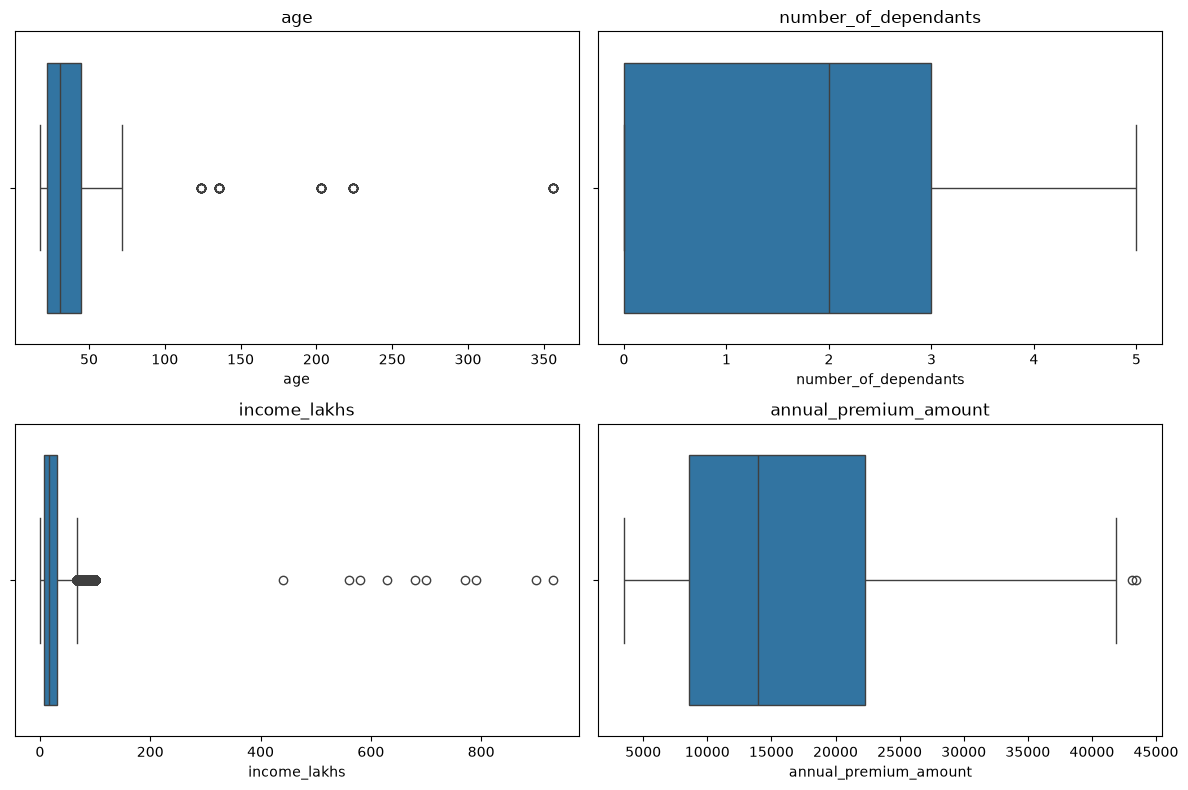

In [23]:
numeric_columns = ['age', 'number_of_dependants', 'income_lakhs', 'annual_premium_amount']

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 8)) #==> Create a figure with 2 rows and 2 columns
axes = axes.flatten() #==>Flatten the axes array for easy iteration
for i, col in enumerate(numeric_columns): #==>Plot each boxplot
    sns.boxplot(x=df[col], ax=axes[i])
    axes[i].set_title(col)
plt.tight_layout() # Adjust spacing
plt.show()

Analysis
1. income_lakhs: A few People income much higher than 400 Lakhs per annum, we will treat them
2. age: Treating age outliers by dropping age values > 100 (age = 100 as threshold)
3. annual_premium amount: People do have the high premium packages

In [27]:
df['age'].describe()

count    49976.000000
mean        34.591764
std         15.000378
min         18.000000
25%         22.000000
50%         31.000000
75%         45.000000
max        356.000000
Name: age, dtype: float64

In [31]:
df[df['age'] > 100]['age'].unique()

array([224, 124, 136, 203, 356])

In [33]:
df[df['age'] > 100]['age'].count()

np.int64(58)

In [34]:
df1 = df[df['age'] < 100]

In [35]:
df1.describe()

,age,number_of_dependants,income_lakhs,annual_premium_amount
count,49918.000000,49918.000000,49918.000000,49918.000000
mean,34.401839,1.717617,23.025141,15766.589286
std,13.681600,1.492074,24.227912,8419.137327
min,18.000000,0.000000,1.000000,3501.000000
25%,22.000000,0.000000,7.000000,8608.000000
50%,31.000000,2.000000,17.000000,13928.000000
75%,45.000000,3.000000,31.000000,22272.000000
max,72.000000,5.000000,930.000000,43471.000000


INCOME COLOUMN OUTLIERS

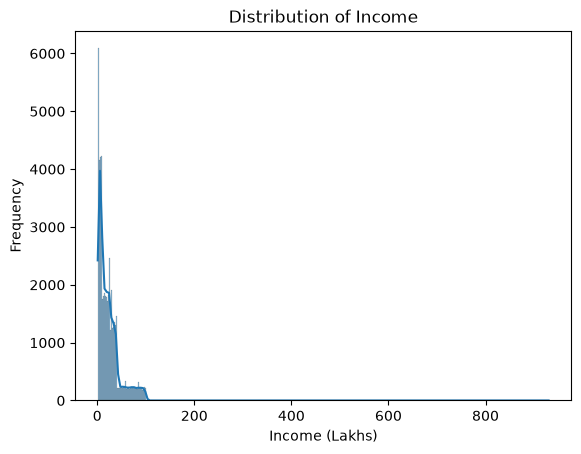

In [39]:

sns.histplot(df['income_lakhs'], kde=True)

plt.title('Distribution of Income')
plt.xlabel('Income (Lakhs)')
plt.ylabel('Frequency')

plt.show()

count    49976.000000
mean        23.021150
std         24.221794
min          1.000000
25%          7.000000
50%         17.000000
75%         31.000000
90%         54.000000
95%         77.000000
99%         96.000000
max        930.000000
Name: income_lakhs, dtype: float64
Missing values: 0
Negative values: 0


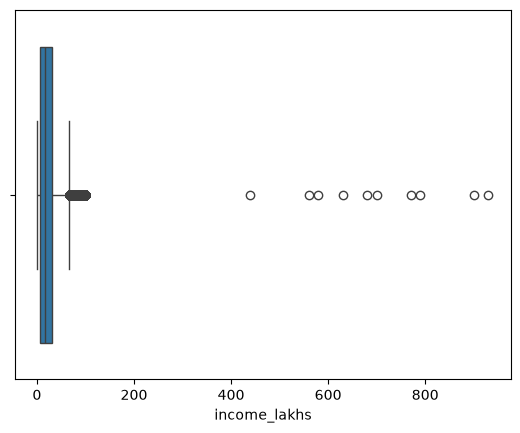

In [40]:

col = 'income_lakhs'

print(df[col].describe(
    percentiles=[.25, .50, .75, .90, .95, .99]
))

print("Missing values:", df[col].isna().sum())
print("Negative values:", (df[col] < 0).sum())

sns.boxplot(x=df[col])
plt.show()

In [45]:
col = 'income_lakhs'

print(df[col].nlargest(20))
print("Values above 67 lakhs:", (df[col] > 67).sum())
print("Values above 96 lakhs:", (df[col] > 96).sum())
print("Values above 100 lakhs:", (df[col] > 100).sum())

10337    930
9021     900
15437    790
35446    770
11456    700
40970    680
7775     630
10639    580
2635     560
4220     440
311      100
362      100
3220     100
3818     100
4413     100
5259     100
6528     100
6732     100
7332     100
8605     100
Name: income_lakhs, dtype: int64
Values above 67 lakhs: 3560
Values above 96 lakhs: 447
Values above 100 lakhs: 10


In [46]:
#Using IQR Method for Outlier handling
def get_iqr_bounds(col):
    Q1, Q3 = col.quantile([0.25, 0.75])
    IQR = Q3-Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return lower_bound, upper_bound

lower, upper = get_iqr_bounds(df1['income_lakhs'])
lower, upper

(-29.0, 67.0)

In [47]:
quantile_threshold  = df1.income_lakhs.quantile(0.999) #====Threshold to evaluate distribution of income
quantile_threshold

np.float64(100.0)

In [48]:
#====Not significant number of people have incomes more than 100 lakh as more than 99 % people have income less than 100 lakhs, so dropping these records
df1[df1['income_lakhs'] > quantile_threshold].shape 

(10, 13)

In [49]:
df2 = df1[df.income_lakhs <= quantile_threshold].copy()  #== Dropping records where income_lakhs> 100
df2.shape

(49908, 13)

Studying the distribution of metrics(Univariate Analysis)

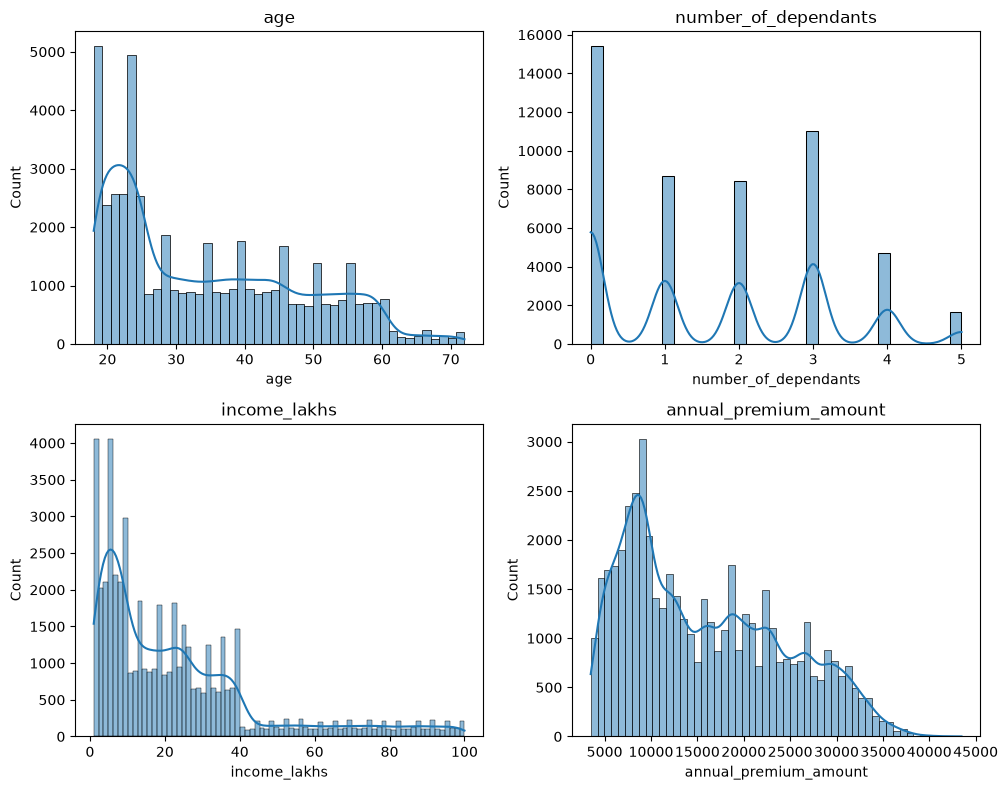

In [50]:
fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(10, 8))  # Adjust the size as necessary

for i, column in enumerate(numeric_columns):
    ax = axs[i//2, i%2]  # Determines the position of the subplot in the grid
    sns.histplot(df2[column], kde=True, ax=ax)
    ax.set_title(column)

plt.tight_layout()
plt.show()

Bivariate Analysis: Numeric Columns

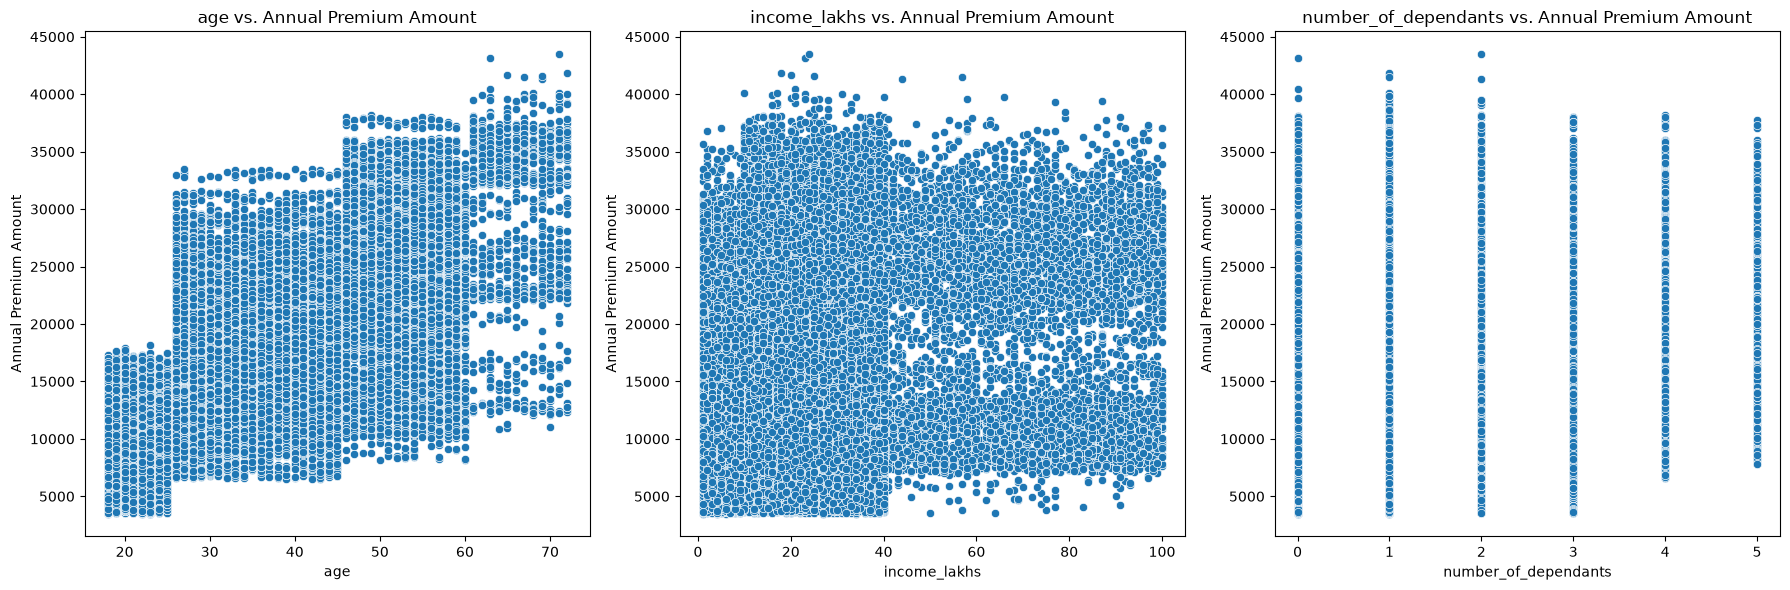

In [51]:
# Studying correlation of different metrics with Annual_premium_amount
numeric_features = ['age', 'income_lakhs', 'number_of_dependants']

fig, axes = plt.subplots(1, len(numeric_features), figsize=(18, 6))  # Adjust figure size as necessary

for ax, column in zip(axes, numeric_features):
    sns.scatterplot(x=df2[column], y=df2['annual_premium_amount'], ax=ax)
    ax.set_title(f'{column} vs. Annual Premium Amount')
    ax.set_xlabel(column)
    ax.set_ylabel('Annual Premium Amount')

plt.tight_layout()  # Adjust layout
plt.show()

# CATEGORICAL COLUMNS

In [52]:
# Checking for unique data in various cols
categorical_cols = ['gender', 'region', 'marital_status', 'bmi_category', 'smoking_status', 'employment_status', 'income_level', 'medical_history', 'insurance_plan']
for col in categorical_cols:
    print(col, ":", df2[col].unique())

gender : <ArrowStringArray>
['Male', 'Female']
Length: 2, dtype: str
region : <ArrowStringArray>
['Northwest', 'Southeast', 'Northeast', 'Southwest']
Length: 4, dtype: str
marital_status : <ArrowStringArray>
['Unmarried', 'Married']
Length: 2, dtype: str
bmi_category : <ArrowStringArray>
['Normal', 'Obesity', 'Overweight', 'Underweight']
Length: 4, dtype: str
smoking_status : <ArrowStringArray>
[    'No Smoking',        'Regular',     'Occasional',      'Smoking=0',
 'Does Not Smoke',    'Not Smoking']
Length: 6, dtype: str
employment_status : <ArrowStringArray>
['Salaried', 'Self-Employed', 'Freelancer']
Length: 3, dtype: str
income_level : <ArrowStringArray>
['<10L', '10L - 25L', '> 40L', '25L - 40L']
Length: 4, dtype: str
medical_history : <ArrowStringArray>
[                           'Diabetes',                 'High blood pressure',
                          'No Disease',      'Diabetes & High blood pressure',
                             'Thyroid',                       'Heart d

In [76]:
df2['smoking_status'].replace({
    'Smoking=0' : 'No Smoking',
    'Does Not Smoke' : 'No Smoking',
    'Not Smoking' : 'No Smoking'
}, inplace = True) 
df2['smoking_status'].unique()

<ArrowStringArray>
[    'No Smoking',        'Regular',     'Occasional',      'Smoking=0',
 'Does Not Smoke',    'Not Smoking']
Length: 6, dtype: str

# Univariate Analysis

In [54]:
pct_count = df2['gender'].value_counts(normalize=True) 
pct_count

gender
Male      0.549631
Female    0.450369
Name: proportion, dtype: float64

<Axes: xlabel='gender'>

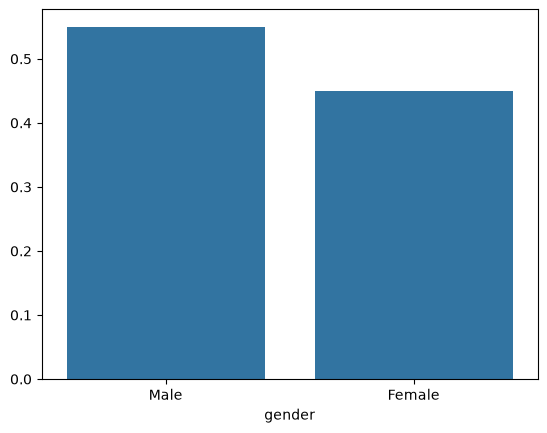

In [55]:
sns.barplot(x = pct_count.index, y = pct_count.values)

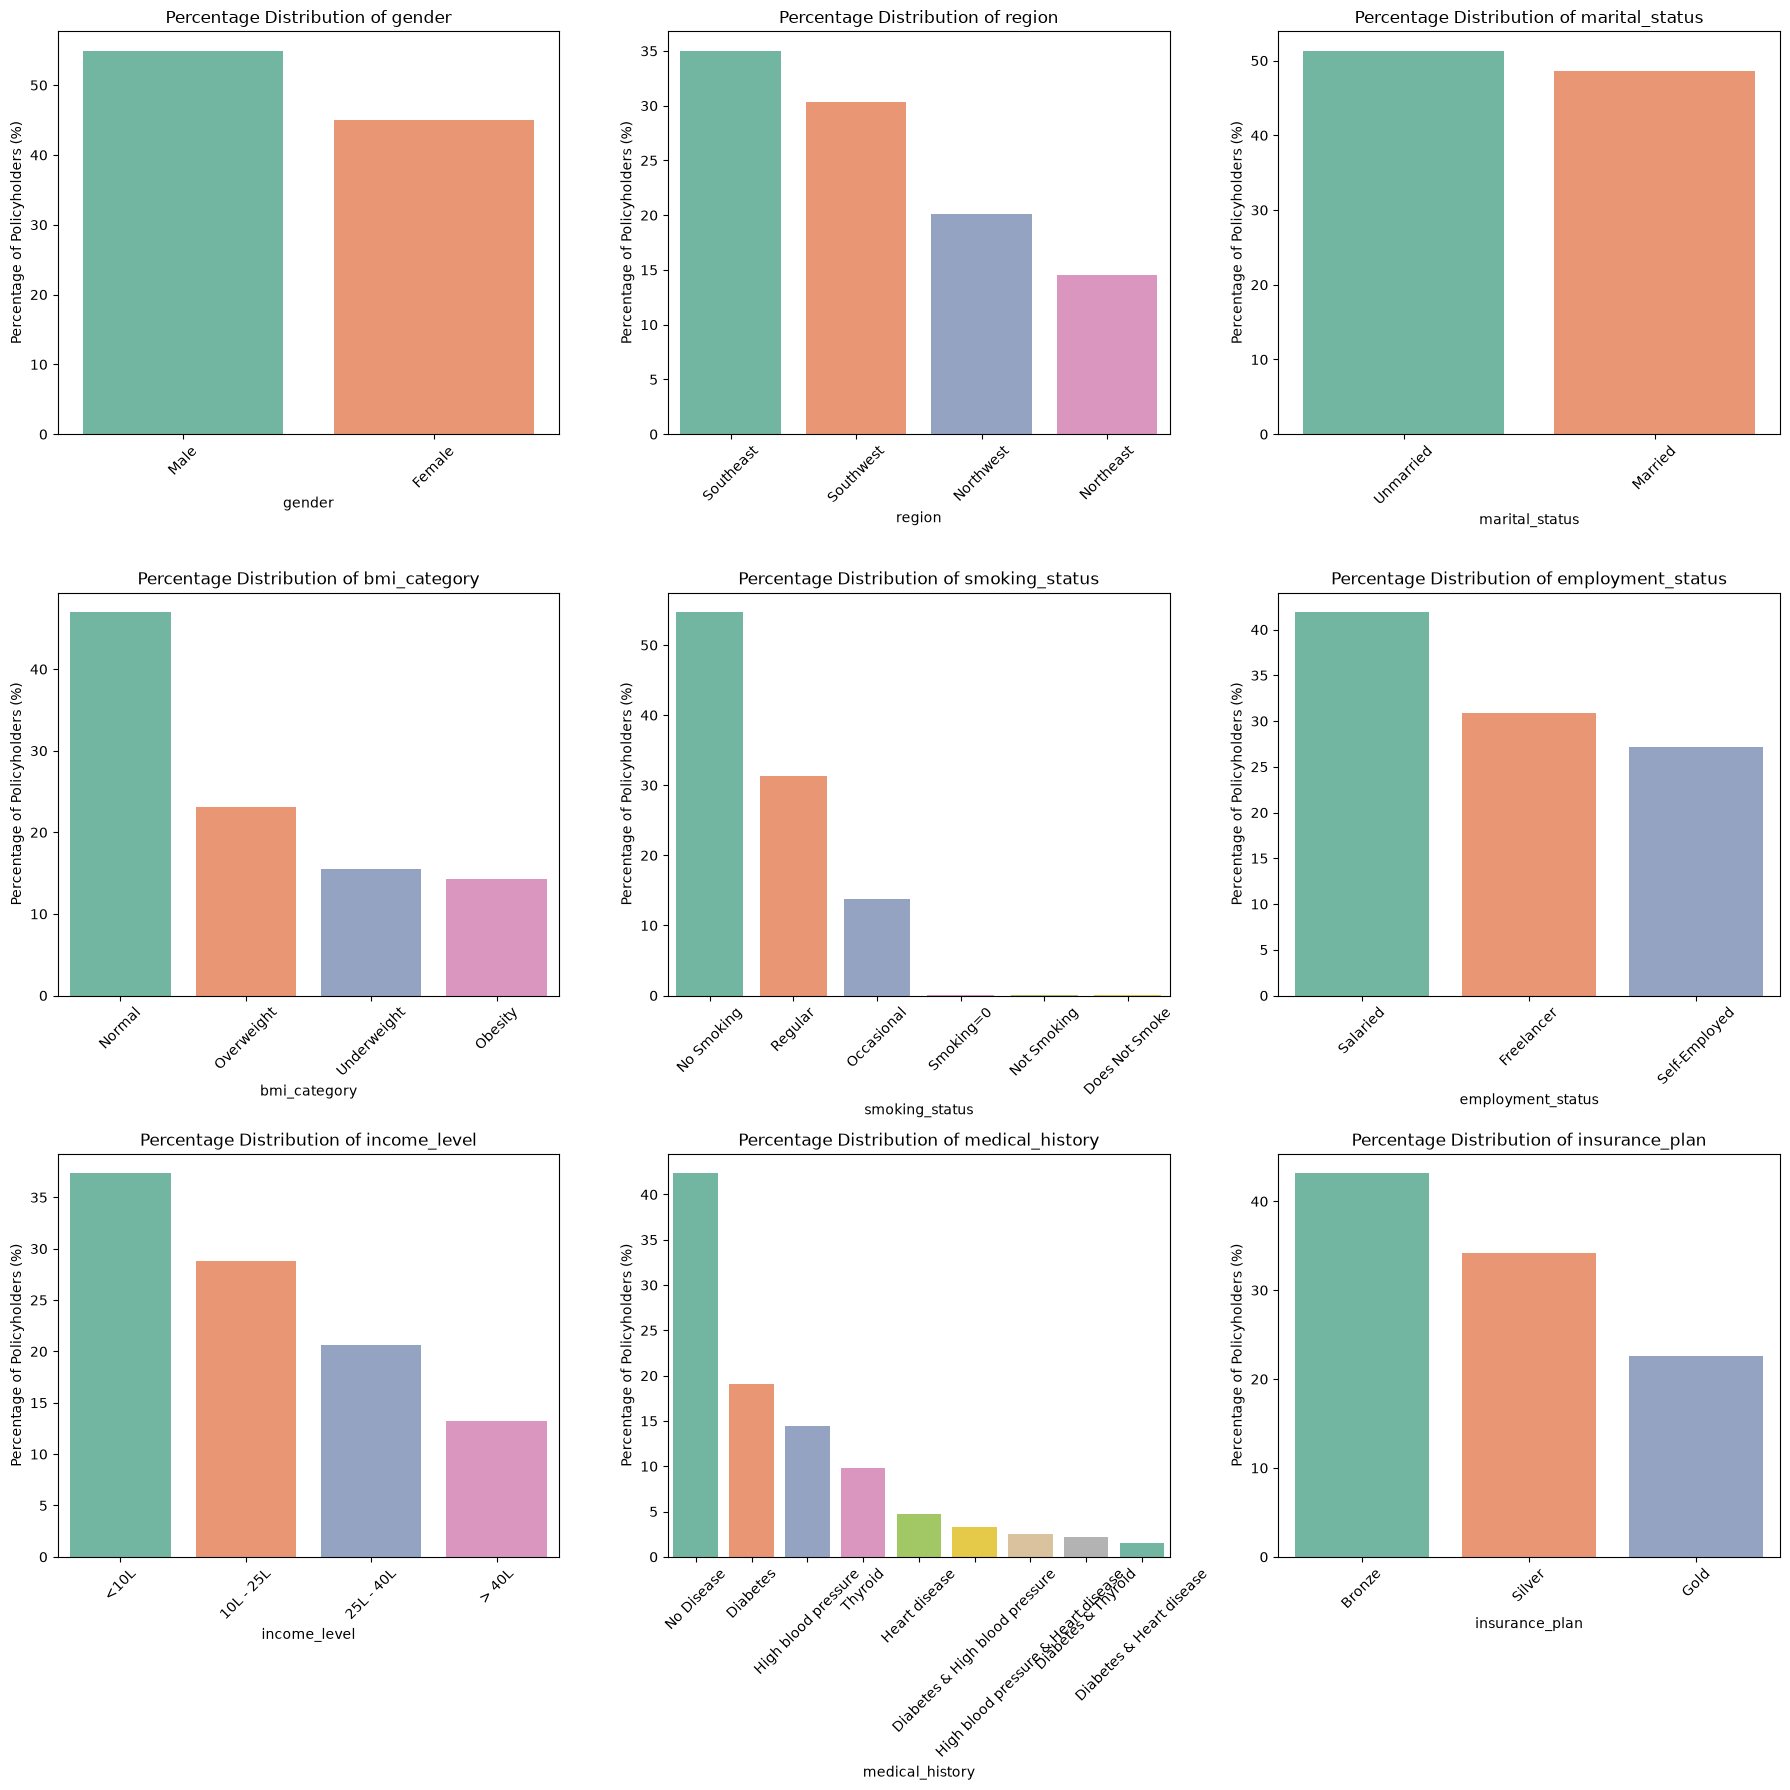

In [60]:
fig, axes = plt.subplots(3, 3, figsize=(18, 18))
axes = axes.flatten()

for ax, column in zip(axes, categorical_cols):

    
    category_counts = df2[column].value_counts(normalize=True) * 100

    
    plot_data = category_counts.reset_index()
    plot_data.columns = [column, 'Percentage']

    
    sns.barplot(
        data=plot_data,
        x=column,
        y='Percentage',
        hue=column,
        palette='Set2',
        legend=False,
        ax=ax
    )

    ax.set_title(f'Percentage Distribution of {column}')
    ax.set_ylabel('Percentage of Policyholders (%)')
    ax.set_xlabel(column)
    ax.tick_params(axis='x', rotation=45)
    
for ax in axes[len(categorical_cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

insurance_plan  Bronze  Gold  Silver
income_level                        
10L - 25L         5307  3880    5182
25L - 40L         3683  2840    3750
<10L             12226   931    5486
> 40L              329  3653    2641


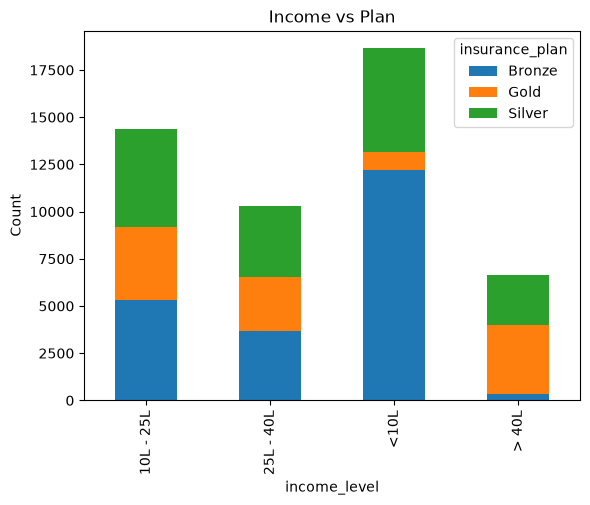

In [61]:
# Cross-tabulation of gender and smoking status
crosstab = pd.crosstab(df2['income_level'], df2['insurance_plan'])
print(crosstab)

# Plotting the crosstab
crosstab.plot(kind='bar', stacked=True)
plt.title('Income vs Plan')
plt.ylabel('Count')
plt.show()

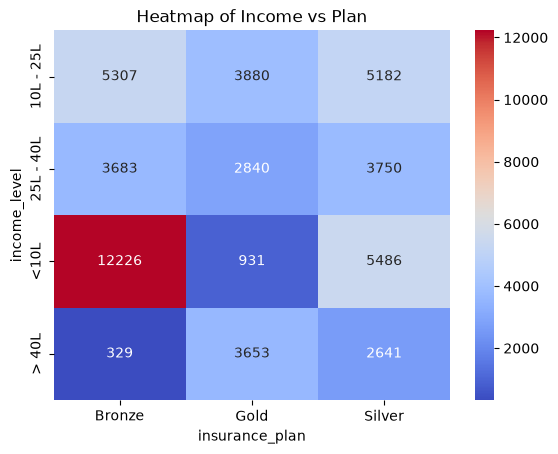

In [62]:
sns.heatmap(crosstab, annot=True, fmt="d", cmap="coolwarm")
plt.title('Heatmap of Income vs Plan')
plt.show()

In [63]:
df.head()

,age,gender,region,marital_status,number_of_dependants,bmi_category,smoking_status,employment_status,income_level,income_lakhs,medical_history,insurance_plan,annual_premium_amount
0,26,Male,Northwest,Unmarried,0,Normal,No Smoking,Salaried,<10L,6,Diabetes,Bronze,9053
1,29,Female,Southeast,Married,2,Obesity,Regular,Salaried,<10L,6,Diabetes,Bronze,16339
2,49,Female,Northeast,Married,2,Normal,No Smoking,Self-Employed,10L - 25L,20,High blood pressure,Silver,18164
3,30,Female,Southeast,Married,3,Normal,No Smoking,Salaried,> 40L,77,No Disease,Gold,20303
4,18,Male,Northeast,Unmarried,0,Overweight,Regular,Self-Employed,> 40L,99,High blood pressure,Silver,13365


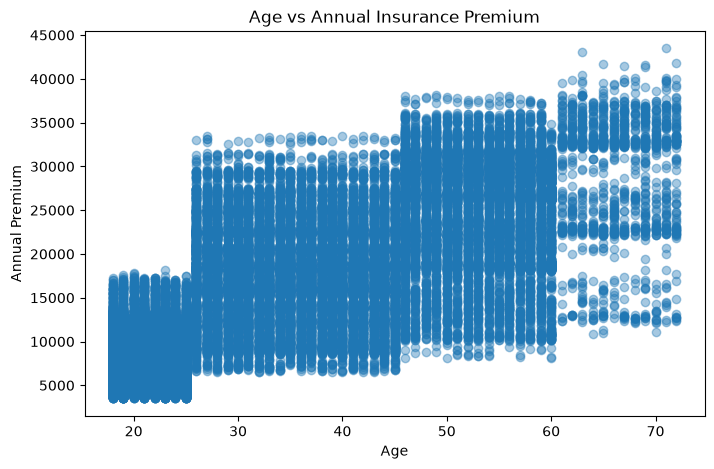

In [65]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(
    df2["age"],
    df2["annual_premium_amount"],
    alpha=0.4
)
plt.xlabel("Age")
plt.ylabel("Annual Premium")
plt.title("Age vs Annual Insurance Premium")
plt.show()

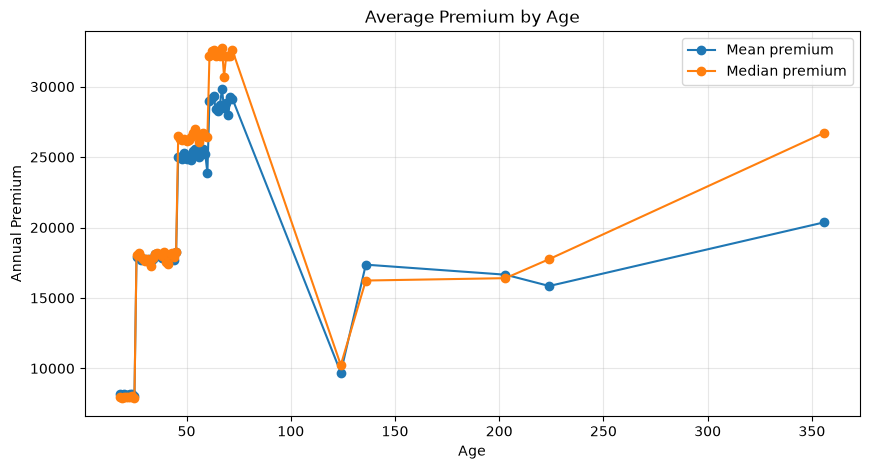

In [66]:
import matplotlib.pyplot as plt

age_stats = (
    df.groupby("age")["annual_premium_amount"]
    .agg(["mean", "median"])
    .reset_index()
)

plt.figure(figsize=(10, 5))

plt.plot(
    age_stats["age"],
    age_stats["mean"],
    marker="o",
    label="Mean premium"
)

plt.plot(
    age_stats["age"],
    age_stats["median"],
    marker="o",
    label="Median premium"
)

plt.xlabel("Age")
plt.ylabel("Annual Premium")
plt.title("Average Premium by Age")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [74]:
print(df2["region"].value_counts())
print(df2["region"].value_counts(normalize=True) * 100)

region
Southeast    17487
Southwest    15124
Northwest    10028
Northeast     7269
Name: count, dtype: int64
region
Southeast    35.038471
Southwest    30.303759
Northwest    20.092971
Northeast    14.564799
Name: proportion, dtype: float64


In [73]:
print(df2["marital_status"].value_counts())
print(df2["marital_status"].value_counts(normalize=True) * 100)

marital_status
Unmarried    25630
Married      24278
Name: count, dtype: int64
marital_status
Unmarried    51.354492
Married      48.645508
Name: proportion, dtype: float64


In [72]:
print(df2["number_of_dependants"].value_counts().sort_index())
print(df2["number_of_dependants"].describe())

number_of_dependants
0    15404
1     8701
2     8408
3    11024
4     4720
5     1651
Name: count, dtype: int64
count    49908.000000
mean         1.717640
std          1.492032
min          0.000000
25%          0.000000
50%          2.000000
75%          3.000000
max          5.000000
Name: number_of_dependants, dtype: float64


In [71]:
print(df2["bmi_category"].value_counts())
print(df2["bmi_category"].dtype)

bmi_category
Normal         23469
Overweight     11541
Underweight     7752
Obesity         7146
Name: count, dtype: int64
str


In [75]:
print(df2["smoking_status"].value_counts())

print(
    df2["smoking_status"].value_counts(normalize=True) * 100
)

print(df2["smoking_status"].dtype)

smoking_status
No Smoking        27321
Regular           15664
Occasional         6901
Smoking=0             8
Not Smoking           8
Does Not Smoke        6
Name: count, dtype: int64
smoking_status
No Smoking        54.742727
Regular           31.385750
Occasional        13.827442
Smoking=0          0.016029
Not Smoking        0.016029
Does Not Smoke     0.012022
Name: proportion, dtype: float64
str


In [77]:
smoking_mapping = {
    "No Smoking": "No Smoking",
    "Smoking=0": "No Smoking",
    "Not Smoking": "No Smoking",
    "Does Not Smoke": "No Smoking",
    "Regular": "Regular",
    "Occasional": "Occasional"
}

df2["smoking_status"] = df2["smoking_status"].replace(
    smoking_mapping
)

In [79]:
df2['smoking_status'].unique()

<ArrowStringArray>
['No Smoking', 'Regular', 'Occasional']
Length: 3, dtype: str

In [81]:
print(df2["employment_status"].value_counts())

print(
    df2["employment_status"].value_counts(normalize=True) * 100
)

print("Data type:", df2["employment_status"].dtype)
print("Missing values:", df2["employment_status"].isna().sum())

employment_status
Salaried         20932
Freelancer       15399
Self-Employed    13577
Name: count, dtype: int64
employment_status
Salaried         41.941172
Freelancer       30.854773
Self-Employed    27.204055
Name: proportion, dtype: float64
Data type: str
Missing values: 0


In [82]:
print(df2["income_level"].value_counts())

print(
    df2["income_level"].value_counts(normalize=True) * 100
)

print("Data type:", df2["income_level"].dtype)
print("Missing values:", df2["income_level"].isna().sum())

income_level
<10L         18643
10L - 25L    14369
25L - 40L    10273
> 40L         6623
Name: count, dtype: int64
income_level
<10L         37.354733
10L - 25L    28.790975
25L - 40L    20.583874
> 40L        13.270418
Name: proportion, dtype: float64
Data type: str
Missing values: 0


In [83]:
print(df2["income_lakhs"].describe())
print("Data type:", df2["income_lakhs"].dtype)
print("Missing values:", df2["income_lakhs"].isna().sum())
print("Unique values:", df2["income_lakhs"].nunique())

count    49908.000000
mean        22.889897
std         22.170699
min          1.000000
25%          7.000000
50%         17.000000
75%         31.000000
max        100.000000
Name: income_lakhs, dtype: float64
Data type: int64
Missing values: 0
Unique values: 100


In [84]:
print(df2["medical_history"].value_counts())
print("Data type:", df2["medical_history"].dtype)
print("Missing values:", df2["medical_history"].isna().sum())

medical_history
No Disease                             21138
Diabetes                                9533
High blood pressure                     7209
Thyroid                                 4917
Heart disease                           2343
Diabetes & High blood pressure          1641
High blood pressure & Heart disease     1273
Diabetes & Thyroid                      1115
Diabetes & Heart disease                 739
Name: count, dtype: int64
Data type: str
Missing values: 0


In [85]:
df3 = df2.copy(deep=True)

In [86]:
df3["has_diabetes"] = (
    df2["medical_history"].str.contains(
        "Diabetes", case=False, na=False
    ).astype(int)
)

df3["has_high_bp"] = (
    df2["medical_history"].str.contains(
        "High blood pressure", case=False, na=False
    ).astype(int)
)

df3["has_thyroid"] = (
    df2["medical_history"].str.contains(
        "Thyroid", case=False, na=False
    ).astype(int)
)

df3["has_heart_disease"] = (
    df2["medical_history"].str.contains(
        "Heart disease", case=False, na=False
    ).astype(int)
)

df3["has_no_disease"] = (
    df2["medical_history"].eq("No Disease").astype(int)
)

In [87]:
df3.head()

,age,gender,region,marital_status,number_of_dependants,bmi_category,smoking_status,employment_status,income_level,income_lakhs,medical_history,insurance_plan,annual_premium_amount,has_diabetes,has_high_bp,has_thyroid,has_heart_disease,has_no_disease
0,26,Male,Northwest,Unmarried,0,Normal,No Smoking,Salaried,<10L,6,Diabetes,Bronze,9053,1,0,0,0,0
1,29,Female,Southeast,Married,2,Obesity,Regular,Salaried,<10L,6,Diabetes,Bronze,16339,1,0,0,0,0
2,49,Female,Northeast,Married,2,Normal,No Smoking,Self-Employed,10L - 25L,20,High blood pressure,Silver,18164,0,1,0,0,0
3,30,Female,Southeast,Married,3,Normal,No Smoking,Salaried,> 40L,77,No Disease,Gold,20303,0,0,0,0,1
4,18,Male,Northeast,Unmarried,0,Overweight,Regular,Self-Employed,> 40L,99,High blood pressure,Silver,13365,0,1,0,0,0


In [88]:
print(df2["insurance_plan"].value_counts())
print("Data type:", df2["insurance_plan"].dtype)
print("Missing values:", df2["insurance_plan"].isna().sum())

insurance_plan
Bronze    21545
Silver    17059
Gold      11304
Name: count, dtype: int64
Data type: str
Missing values: 0


In [89]:
print(df2["annual_premium_amount"].describe())
print("Data type:", df2["annual_premium_amount"].dtype)
print("Missing values:", df2["annual_premium_amount"].isna().sum())
print("Skewness:", df2["annual_premium_amount"].skew())

count    49908.000000
mean     15765.739641
std       8418.674061
min       3501.000000
25%       8608.000000
50%      13928.000000
75%      22270.500000
max      43471.000000
Name: annual_premium_amount, dtype: float64
Data type: int64
Missing values: 0
Skewness: 0.5182683783289865


In [90]:
#seprate target and feature columns
X = df3.drop(columns=["annual_premium_amount"])
y = df3["annual_premium_amount"]

In [93]:
# Step 2: Identify numerical columns
print("\nNumerical columns:")
print(X.select_dtypes(include="number").columns.tolist())

# Step 3: Identify categorical columns
print("\nCategorical columns:")
print(X.select_dtypes(include=["object", "category"]).columns.tolist())


Numerical columns:
['age', 'number_of_dependants', 'income_lakhs', 'has_diabetes', 'has_high_bp', 'has_thyroid', 'has_heart_disease', 'has_no_disease']

Categorical columns:
['gender', 'region', 'marital_status', 'bmi_category', 'smoking_status', 'employment_status', 'income_level', 'medical_history', 'insurance_plan']


In [94]:

from sklearn.model_selection import train_test_split

# Exclude engineered medical-history indicators for baseline
medical_indicators = [
    "has_diabetes",
    "has_high_bp",
    "has_thyroid",
    "has_heart_disease",
    "has_no_disease"
]

X = X.drop(columns=medical_indicators, errors="ignore")

# Define feature groups
numeric_features = [
    "age",
    "number_of_dependants",
    "income_lakhs"
]

categorical_features = [
    "gender",
    "region",
    "marital_status",
    "bmi_category",
    "smoking_status",
    "employment_status",
    "income_level",
    "medical_history",
    "insurance_plan"
]

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (49908, 12)
y shape: (49908,)


In [95]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 39926
Testing samples: 9982


In [96]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

numeric_transformer = Pipeline([
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# MODEL TRAINING

In [97]:

from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Build the complete pipeline
lr_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

# Train
lr_model.fit(X_train, y_train)

# Predict on the test set
y_pred = lr_model.predict(X_test)

# Evaluate
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE:  {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²:   {r2:.4f}")


MAE:  1625.63
RMSE: 2129.74
R²:   0.9356


## Random Forest

In [98]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=200,
        max_depth=None,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

print(f"Random Forest MAE:  {rf_mae:.2f}")
print(f"Random Forest RMSE: {rf_rmse:.2f}")
print(f"Random Forest R²:   {rf_r2:.4f}")


Random Forest MAE:  793.41
Random Forest RMSE: 1189.38
Random Forest R²:   0.9799


                                              feature  importance
0                                            num__age    0.590888
35                           cat__insurance_plan_Gold    0.244715
34                         cat__insurance_plan_Bronze    0.059323
36                         cat__insurance_plan_Silver    0.035858
17                        cat__smoking_status_Regular    0.014702
12                          cat__bmi_category_Obesity    0.011659
29                 cat__medical_history_Heart disease    0.007893
32                    cat__medical_history_No Disease    0.007522
13                       cat__bmi_category_Overweight    0.004854
2                                   num__income_lakhs    0.004258
31  cat__medical_history_High blood pressure & Hea...    0.003797
11                           cat__bmi_category_Normal    0.002620
26      cat__medical_history_Diabetes & Heart disease    0.002276
27  cat__medical_history_Diabetes & High blood pre...    0.001283
1         

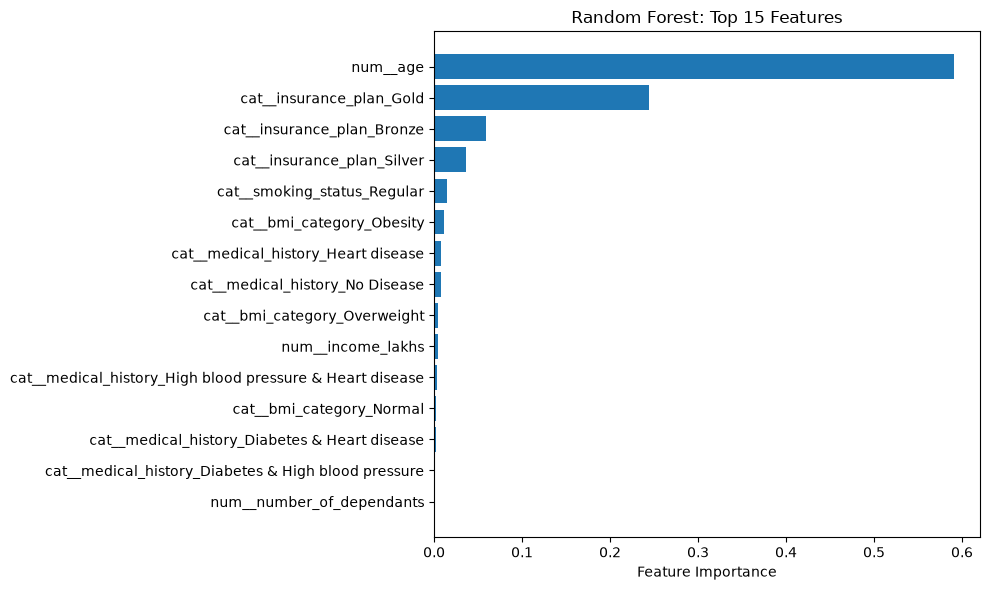

In [99]:

import pandas as pd
import matplotlib.pyplot as plt

# Extract the fitted preprocessing and Random Forest components
fitted_preprocessor = rf_model.named_steps["preprocessor"]
rf = rf_model.named_steps["regressor"]

# Get names after one-hot encoding
feature_names = fitted_preprocessor.get_feature_names_out()

# Build importance table
importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": rf.feature_importances_
})

importance_df = importance_df.sort_values(
    "importance", ascending=False
)

print(importance_df.head(15))

# Plot top 15 features
top_features = importance_df.head(15).sort_values("importance")

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.xlabel("Feature Importance")
plt.title("Random Forest: Top 15 Features")
plt.tight_layout()
plt.show()


In [100]:
premium_by_plan = df3.pivot_table(
    index="age",
    columns="insurance_plan",
    values="annual_premium_amount",
    aggfunc="mean"
)

print(premium_by_plan.head(15))

insurance_plan        Bronze          Gold        Silver
age                                                     
18               6914.348424  13648.865031  10355.500787
19               6850.007198  13971.392157  10390.300169
20               6912.885404  13879.323529  10352.059783
21               6804.456170  13927.051136  10460.585977
22               6918.295652  13927.444444  10361.419469
23               6845.244957  14022.035294  10360.357877
24               6954.931293  13770.726190  10384.839928
25               6911.974332  13692.825175  10371.276923
26              12214.218121  25128.396552  19093.655612
27              12092.893891  25017.405941  18889.030162
28              12057.965300  25091.850267  18698.626214
29              12185.124620  25475.933702  18804.156322
30              12013.673267  25354.839080  18752.426049
31              12097.576792  25077.867052  18597.939024
32              12186.843949  25007.089385  18934.350877


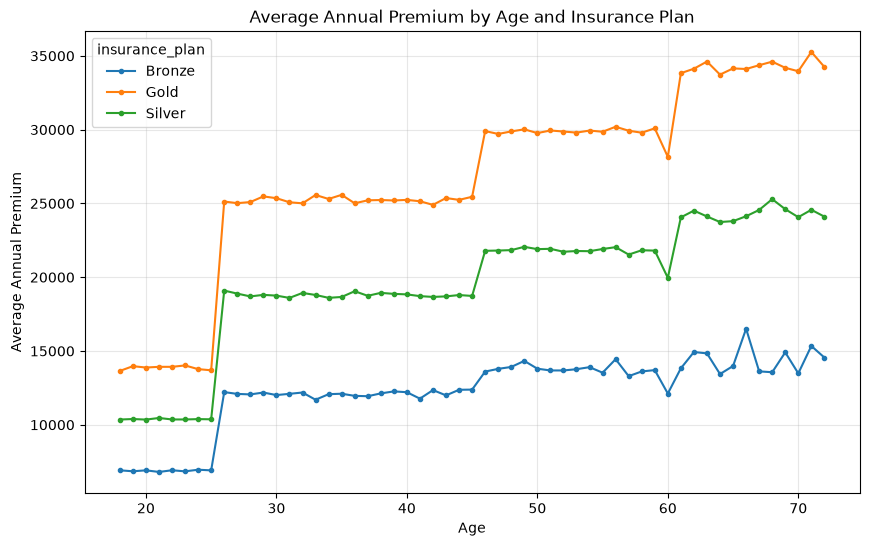

In [101]:
import matplotlib.pyplot as plt

premium_by_plan.plot(figsize=(10, 6), marker=".")
plt.title("Average Annual Premium by Age and Insurance Plan")
plt.xlabel("Age")
plt.ylabel("Average Annual Premium")
plt.grid(alpha=0.3)
plt.show()

In [102]:
from sklearn.model_selection import cross_validate

cv_results = cross_validate(
    rf_model,
    X_train,
    y_train,
    cv=5,
    scoring={
        "mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error",
        "r2": "r2"
    },
    n_jobs=-1
)

print("CV MAE:", -cv_results["test_mae"].mean())
print("CV RMSE:", -cv_results["test_rmse"].mean())
print("CV R2:", cv_results["test_r2"].mean())

CV MAE: 800.2644369674808
CV RMSE: 1197.4605894930337
CV R2: 0.9797924678278902


In [104]:
%pip install xgboost

  Using cached xgboost-3.4.1-py3-none-win_amd64.whl.metadata (2.0 kB)
Using cached xgboost-3.4.1-py3-none-win_amd64.whl (48.9 MB)
Note: you may need to restart the kernel to use updated packages.


In [105]:
from xgboost import XGBRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", XGBRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    ))
])

xgb_model.fit(X_train, y_train)

xgb_pred = xgb_model.predict(X_test)

print("XGBoost MAE:", mean_absolute_error(y_test, xgb_pred))
print(
    "XGBoost RMSE:",
    np.sqrt(mean_squared_error(y_test, xgb_pred))
)
print("XGBoost R²:", r2_score(y_test, xgb_pred))


XGBoost MAE: 766.8408203125
XGBoost RMSE: 1140.0917726218358
XGBoost R²: 0.9815531373023987


In [106]:

from sklearn.model_selection import cross_validate

xgb_cv = cross_validate(
    xgb_model,
    X_train,
    y_train,
    cv=5,
    scoring={
        "mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error",
        "r2": "r2"
    },
    n_jobs=1
)

print("CV MAE:", -xgb_cv["test_mae"].mean())
print("CV RMSE:", -xgb_cv["test_rmse"].mean())
print("CV R²:", xgb_cv["test_r2"].mean())


CV MAE: 777.0252319335938
CV RMSE: 1154.192919921875
CV R²: 0.9812272787094116


In [107]:

# X_train and X_test are based on the original baseline features.
# Reconstruct the alternative features from df3.

medical_indicators = [
    "has_diabetes",
    "has_high_bp",
    "has_thyroid",
    "has_heart_disease",
    "has_no_disease"
]

# Start from the same feature set used in the baseline
X_alt = df3.drop(columns=["annual_premium_amount"])

# Remove the original medical-history category
X_alt = X_alt.drop(columns=["medical_history"])

# Add the five binary indicators
# (Already present in df3)
X_alt[medical_indicators] = df3[medical_indicators]

# Use the same rows as the original X
X_alt = X_alt.loc[X.index]

# Split with the same seed and test size
from sklearn.model_selection import train_test_split

X_train_alt, X_test_alt, y_train_alt, y_test_alt = train_test_split(
    X_alt,
    y,
    test_size=0.2,
    random_state=42
)

print("Alternative feature shape:", X_alt.shape)
print("Training shape:", X_train_alt.shape)
print("Testing shape:", X_test_alt.shape)


Alternative feature shape: (49908, 16)
Training shape: (39926, 16)
Testing shape: (9982, 16)


In [108]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Numerical features, including the medical indicators
numeric_features_alt = [
    "age",
    "number_of_dependants",
    "income_lakhs",
    "has_diabetes",
    "has_high_bp",
    "has_thyroid",
    "has_heart_disease",
    "has_no_disease"
]

# Categorical features, excluding medical_history
categorical_features_alt = [
    "gender",
    "region",
    "marital_status",
    "bmi_category",
    "smoking_status",
    "employment_status",
    "income_level",
    "insurance_plan"
]

preprocessor_alt = ColumnTransformer([
    (
        "num",
        StandardScaler(),
        numeric_features_alt
    ),
    (
        "cat",
        OneHotEncoder(handle_unknown="ignore"),
        categorical_features_alt
    )
])

print("Preprocessing pipeline created.")


Preprocessing pipeline created.


In [109]:

from xgboost import XGBRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

xgb_model_alt = Pipeline([
    ("preprocessor", preprocessor_alt),
    ("regressor", XGBRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    ))
])

xgb_model_alt.fit(X_train_alt, y_train_alt)

pred_alt = xgb_model_alt.predict(X_test_alt)

print("Alternative XGBoost MAE:",
      mean_absolute_error(y_test_alt, pred_alt))
print("Alternative XGBoost RMSE:",
      np.sqrt(mean_squared_error(y_test_alt, pred_alt)))
print("Alternative XGBoost R²:",
      r2_score(y_test_alt, pred_alt))


Alternative XGBoost MAE: 766.443115234375
Alternative XGBoost RMSE: 1140.8923042951951
Alternative XGBoost R²: 0.9815272688865662


In [110]:

from sklearn.model_selection import cross_validate

cv_alt = cross_validate(
    xgb_model_alt,
    X_train_alt,
    y_train_alt,
    cv=5,
    scoring={
        "mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error",
        "r2": "r2"
    },
    n_jobs=1
)

print("Alternative CV MAE:",
      -cv_alt["test_mae"].mean())
print("Alternative CV RMSE:",
      -cv_alt["test_rmse"].mean())
print("Alternative CV R²:",
      cv_alt["test_r2"].mean())


Alternative CV MAE: 774.5622436523438
Alternative CV RMSE: 1153.9814697265624
Alternative CV R²: 0.9812342643737793


In [111]:
#remove income level

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate
from xgboost import XGBRegressor

# Remove income_level from the original feature sets
X_train_income = X_train.drop(columns=["income_level"])
X_test_income = X_test.drop(columns=["income_level"])

# Update the preprocessing column lists
numeric_features_income = [
    "age",
    "number_of_dependants",
    "income_lakhs"
]

categorical_features_income = [
    "gender",
    "region",
    "marital_status",
    "bmi_category",
    "smoking_status",
    "employment_status",
    "medical_history",
    "insurance_plan"
]

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor_income = ColumnTransformer([
    ("num", StandardScaler(), numeric_features_income),
    ("cat", OneHotEncoder(handle_unknown="ignore"),
     categorical_features_income)
])

xgb_model_income = Pipeline([
    ("preprocessor", preprocessor_income),
    ("regressor", XGBRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    ))
])

cv_income = cross_validate(
    xgb_model_income,
    X_train_income,
    y_train,
    cv=5,
    scoring={
        "mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error",
        "r2": "r2"
    },
    n_jobs=1
)

print("CV MAE:", -cv_income["test_mae"].mean())
print("CV RMSE:", -cv_income["test_rmse"].mean())
print("CV R²:", cv_income["test_r2"].mean())


CV MAE: 774.95859375
CV RMSE: 1152.885205078125
CV R²: 0.9812703967094422


In [112]:
# Train the revised model
xgb_model_income.fit(X_train_income, y_train)

# Predict on the test set
y_pred_income = xgb_model_income.predict(X_test_income)

# Calculate evaluation metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred_income)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_income))
r2 = r2_score(y_test, y_pred_income)

print("Test MAE:", mae)
print("Test RMSE:", rmse)
print("Test R²:", r2)

Test MAE: 765.9779663085938
Test RMSE: 1140.3622231554323
Test R²: 0.9815444350242615


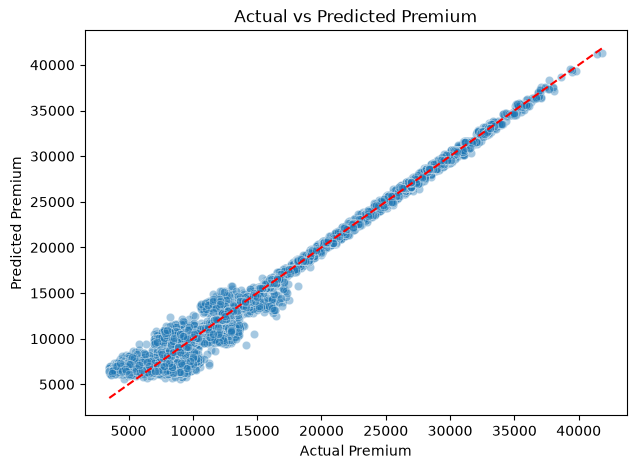

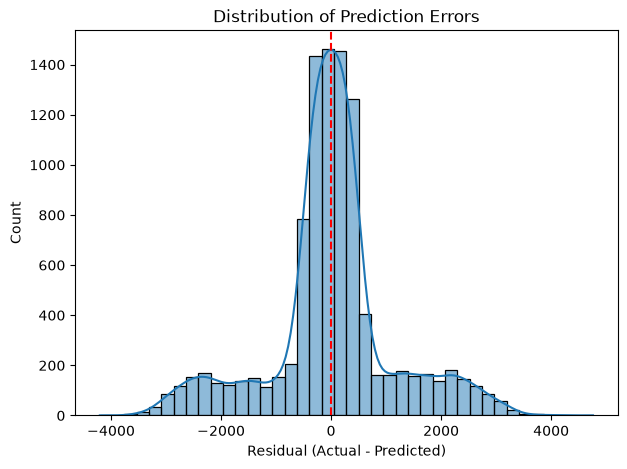

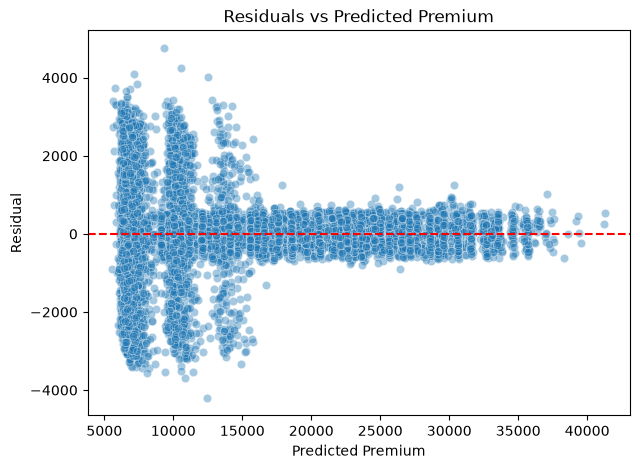

In [113]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Create a dataframe of actual and predicted premiums
results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred_income
})

results["Residual"] = results["Actual"] - results["Predicted"]
results["Absolute_Error"] = results["Residual"].abs()

# 1. Actual vs predicted
plt.figure(figsize=(7, 5))
sns.scatterplot(data=results, x="Actual", y="Predicted", alpha=0.4)

min_val = min(results["Actual"].min(), results["Predicted"].min())
max_val = max(results["Actual"].max(), results["Predicted"].max())

plt.plot([min_val, max_val], [min_val, max_val], "r--")
plt.xlabel("Actual Premium")
plt.ylabel("Predicted Premium")
plt.title("Actual vs Predicted Premium")
plt.show()

# 2. Residual distribution
plt.figure(figsize=(7, 5))
sns.histplot(results["Residual"], bins=40, kde=True)
plt.axvline(0, color="red", linestyle="--")
plt.xlabel("Residual (Actual - Predicted)")
plt.title("Distribution of Prediction Errors")
plt.show()

# 3. Residuals vs predicted values
plt.figure(figsize=(7, 5))
sns.scatterplot(
    data=results,
    x="Predicted",
    y="Residual",
    alpha=0.4
)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted Premium")
plt.ylabel("Residual")
plt.title("Residuals vs Predicted Premium")
plt.show()

In [114]:
# Group predictions by actual premium range
results["Premium_Range"] = pd.cut(
    results["Actual"],
    bins=[0, 10000, 15000, 20000, 25000, 30000, 50000],
    labels=[
        "Below 10k",
        "10k–15k",
        "15k–20k",
        "20k–25k",
        "25k–30k",
        "Above 30k"
    ]
)

# Calculate error metrics for each range
error_analysis = results.groupby(
    "Premium_Range",
    observed=False
).apply(
    lambda group: pd.Series({
        "Count": len(group),
        "MAE": group["Absolute_Error"].mean(),
        "RMSE": np.sqrt((group["Residual"] ** 2).mean()),
        "Mean_Residual": group["Residual"].mean()
    }),
    include_groups=False
)

print(error_analysis.round(2))

                Count      MAE     RMSE  Mean_Residual
Premium_Range                                         
Below 10k      3416.0  1402.53  1676.62        -224.89
10k–15k        1793.0   811.88  1198.25         401.50
15k–20k        1615.0   343.25   547.78         101.94
20k–25k        1387.0   262.40   310.56          -9.95
25k–30k        1049.0   265.28   316.28          12.81
Above 30k       722.0   280.71   334.11          52.69


In [115]:
# Combine test features with prediction results
error_data = X_test.join(
    results[["Actual", "Predicted", "Residual", "Absolute_Error"]]
)

# Focus on customers with actual premiums below 10,000
low_premium = error_data[error_data["Actual"] < 10000].copy()

# Sort customers by absolute prediction error
low_premium = low_premium.sort_values(
    "Absolute_Error",
    ascending=False
)

# Inspect the 15 largest errors
print(
    low_premium[
        [
            "age",
            "gender",
            "insurance_plan",
            "smoking_status",
            "bmi_category",
            "medical_history",
            "income_lakhs",
            "Actual",
            "Predicted",
            "Residual",
            "Absolute_Error"
        ]
    ].head(15).round(2).to_string()
)

       age  gender insurance_plan smoking_status bmi_category                      medical_history  income_lakhs  Actual     Predicted  Residual  Absolute_Error
49686   18    Male         Silver     No Smoking       Normal  High blood pressure & Heart disease            38    8207  12409.419922  -4202.42         4202.42
26638   18    Male         Bronze     No Smoking       Normal                           No Disease            16    9494   5757.669922   3736.33         3736.33
41884   25  Female         Silver     No Smoking  Underweight                           No Disease            77    7163  10863.400391  -3700.39         3700.39
14006   24  Female         Bronze     No Smoking       Normal       Diabetes & High blood pressure             3    4507   8080.910156  -3573.91         3573.91
29479   19  Female         Silver        Regular       Normal                           No Disease             9    7877  11424.019531  -3547.03         3547.03
2671    18  Female         Bronze 

In [116]:
age_plan_analysis = (
    df3.groupby(["age", "insurance_plan"])["annual_premium_amount"]
    .agg(["mean", "min", "max", "count"])
    .round(2)
    .reset_index()
)

# Focus on young customers
young_customers = age_plan_analysis[
    age_plan_analysis["age"].between(18, 30)
]

print(young_customers.to_string(index=False))

 age insurance_plan     mean   min   max  count
  18         Bronze  6914.35  3503 11393   1745
  18           Gold 13648.87 10784 17261    163
  18         Silver 10355.50  7087 13979    635
  19         Bronze  6850.01  3514 11227   1806
  19           Gold 13971.39 10525 17611    153
  19         Silver 10390.30  7049 15527    593
  20         Bronze  6912.89  3505 11260   1658
  20           Gold 13879.32 10611 17878    170
  20         Silver 10352.06  7001 14789    552
  21         Bronze  6804.46  3516 11040   1791
  21           Gold 13927.05 10621 17227    176
  21         Silver 10460.59  7018 14313    599
  22         Bronze  6918.30  3501 11696   1840
  22           Gold 13927.44 10532 17295    162
  22         Silver 10361.42  7006 13938    565
  23         Bronze  6845.24  3501 10847   1735
  23           Gold 14022.04 10600 18186    170
  23         Silver 10360.36  7096 14097    584
  24         Bronze  6954.93  3505 11089   1732
  24           Gold 13770.73 10587 17019

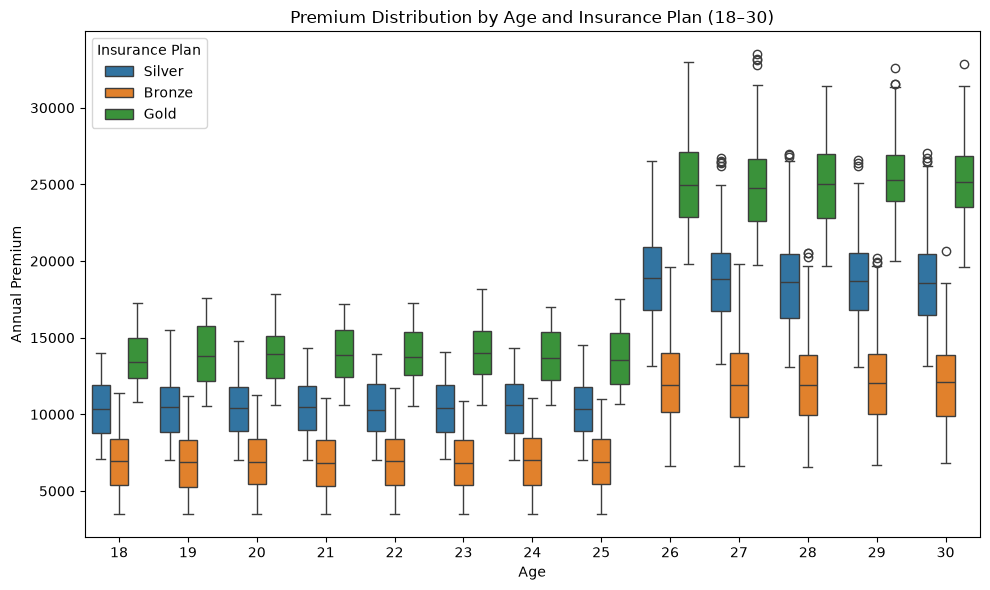

In [117]:
import matplotlib.pyplot as plt
import seaborn as sns

young_df = df3[df3["age"].between(18, 30)]

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=young_df,
    x="age",
    y="annual_premium_amount",
    hue="insurance_plan"
)

plt.title("Premium Distribution by Age and Insurance Plan (18–30)")
plt.xlabel("Age")
plt.ylabel("Annual Premium")
plt.legend(title="Insurance Plan")
plt.tight_layout()
plt.show()

In [118]:
print("Training samples:")
print("Age <= 25:", (X_train_income["age"] <= 25).sum())
print("Age >= 26:", (X_train_income["age"] >= 26).sum())

print("\nTest samples:")
print("Age <= 25:", (X_test_income["age"] <= 25).sum())
print("Age >= 26:", (X_test_income["age"] >= 26).sum())

Training samples:
Age <= 25: 16085
Age >= 26: 23841

Test samples:
Age <= 25: 4001
Age >= 26: 5981


### training two models based on age

In [119]:

from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from xgboost import XGBRegressor
import numpy as np
import pandas as pd

# Split training data by age
train_young = X_train_income["age"] <= 25
train_older = X_train_income["age"] >= 26

X_train_young = X_train_income.loc[train_young]
y_train_young = y_train.loc[train_young]

X_train_older = X_train_income.loc[train_older]
y_train_older = y_train.loc[train_older]

# Split test data by age
test_young = X_test_income["age"] <= 25
test_older = X_test_income["age"] >= 26

X_test_young = X_test_income.loc[test_young]
X_test_older = X_test_income.loc[test_older]

y_test_young = y_test.loc[test_young]
y_test_older = y_test.loc[test_older]

# Create the same XGBoost model configuration
def make_xgb_model():
    return Pipeline([
        ("preprocessor", clone(preprocessor_income)),
        ("regressor", XGBRegressor(
            n_estimators=500,
            learning_rate=0.05,
            max_depth=6,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="reg:squarederror",
            random_state=42,
            n_jobs=-1
        ))
    ])

# Train the two models independently
xgb_young = make_xgb_model()
xgb_older = make_xgb_model()

xgb_young.fit(X_train_young, y_train_young)
xgb_older.fit(X_train_older, y_train_older)

print("Both age-specific models trained successfully.")


Both age-specific models trained successfully.


In [120]:

# Predict each age group
pred_young = xgb_young.predict(X_test_young)
pred_older = xgb_older.predict(X_test_older)

# Combine predictions while preserving original test indices
segmented_predictions = pd.Series(index=y_test.index, dtype=float)

segmented_predictions.loc[X_test_young.index] = pred_young
segmented_predictions.loc[X_test_older.index] = pred_older

# Evaluation helper
def evaluate_model(y_true, y_pred, name):
    print(f"\n{name}")
    print("MAE:", round(mean_absolute_error(y_true, y_pred), 2))
    print("RMSE:", round(np.sqrt(mean_squared_error(y_true, y_pred)), 2))
    print("R²:", round(r2_score(y_true, y_pred), 5))

# Evaluate each segment
evaluate_model(y_test_young, pred_young, "Age <= 25")
evaluate_model(y_test_older, pred_older, "Age >= 26")

# Evaluate the complete test set
evaluate_model(y_test, segmented_predictions, "Combined segmented model")

# Compare against your single-model baseline
evaluate_model(
    y_test,
    y_pred_income,
    "Single XGBoost baseline"
)



Age <= 25
MAE: 1524.08
RMSE: 1777.87
R²: 0.5964

Age >= 26
MAE: 261.48
RMSE: 307.15
R²: 0.99804

Combined segmented model
MAE: 767.56
RMSE: 1150.41
R²: 0.98122

Single XGBoost baseline
MAE: 765.98
RMSE: 1140.36
R²: 0.98154


In [121]:
age_plan_summary = (
    df3.groupby(["age", "insurance_plan"])["annual_premium_amount"]
    .agg(
        count="count",
        mean="mean",
        std="std",
        minimum="min",
        median="median",
        maximum="max"
    )
    .reset_index()
)

# Compare premium variation for younger and older customers
age_plan_summary["age_group"] = np.where(
    age_plan_summary["age"] <= 25,
    "Age <= 25",
    "Age >= 26"
)

group_summary = age_plan_summary.groupby("age_group").apply(
    lambda g: pd.Series({
        "Age-plan groups": len(g),
        "Average within-group std": g["std"].mean(),
        "Average within-group range": (
            g["maximum"] - g["minimum"]
        ).mean()
    }),
    include_groups=False
)

print(group_summary.round(2))

           Age-plan groups  Average within-group std  \
age_group                                              
Age <= 25             24.0                   1787.83   
Age >= 26            141.0                   2500.37   

           Average within-group range  
age_group                              
Age <= 25                     7322.79  
Age >= 26                    11989.77  


In [122]:
import joblib

# Train the final model on the full training split
xgb_model_income.fit(X_train_income, y_train)

# Save the complete pipeline
joblib.dump(
    xgb_model_income,
    "insurance_premium_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!
